# Rotary spectra for Loon data

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplotlib.cm
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
from mpl_toolkits.basemap import Basemap
warnings.simplefilter("ignore")

# For determining which times are day or night
import datetime
import pytz
import timezonefinder
import astral, astral.sun
from tqdm.notebook import tqdm

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()
    
# Replace Basemap with Cartopy:
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

### Constants

In [2]:
# Physical constants
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
Omega = 7.27E-5 # (s-1); the rotation rate of the Earth

# Time series properties
dt = 2 # (minutes) the time step of the interpolated data

# Thresholds for limiting the size of spectra
GW_PERIOD_MIN = 10 # (minutes) the minimum period for frequency-integrated momentum fluxes
GW_PERIOD_MAX = 1*24*60 # (minutes) the maximum GW period

# Wavelet parameters
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98

### Load in the data

In [3]:
flights = pd.read_feather('5_flights_interptime_2daysegments_new_commontime.feather')

# My approach, based on running a few depressurizations through a wavelet analysis, is to mark
# both the depressurization and the data within 2 hours (to the nearsest hour, rounding up) or the 
# width of the depressurization, whichever is bigger, on either side of it.
flights['depressurization'] = 0

# Tropical Pacific
# Segment 284 (Flight I-195)
flights.loc[(flights.flight_id == 'I-195') & 
        (flights.time >= np.datetime64('2014-07-09 07:00:00')) &
        (flights.time <= np.datetime64('2014-07-09 15:00:00')), 'depressurization'] = 1

# Segment 7969 (Flight I-488)
flights.loc[(flights.flight_id == 'I-488') & 
        (flights.time >= np.datetime64('2015-05-21 18:00:00')) &
        (flights.time <= np.datetime64('2015-05-22 10:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-488') & 
        (flights.time >= np.datetime64('2015-05-23 04:00:00')) &
        (flights.time <= np.datetime64('2015-05-23 16:00:00')), 'depressurization'] = 1

# Segment 8041 (Flight I-490)
flights.loc[(flights.flight_id == 'I-490') & 
        (flights.time >= np.datetime64('2015-06-24 07:00:00')) &
        (flights.time <= np.datetime64('2015-06-24 13:00:00')), 'depressurization'] = 1



# Tropical Atlantic
# Segment 6506 (Flight I-436)
flights.loc[(flights.flight_id == 'I-436') & 
        (flights.time >= np.datetime64('2015-04-09 01:00:00')) &
        (flights.time <= np.datetime64('2015-04-09 10:00:00')), 'depressurization'] = 1

# Segment 8957 (Flight NR-215)
flights.loc[(flights.flight_id == 'NR-215') & 
        (flights.time >= np.datetime64('2016-02-19 00:00:00')) &
        (flights.time <= np.datetime64('2016-02-19 13:00:00')), 'depressurization'] = 1



# Indian Ocean
# Segment 58 (Flight L-002)
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-15 18:00:00')) &
        (flights.time <= np.datetime64('2014-02-16 04:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-20 04:00:00')) &
        (flights.time <= np.datetime64('2014-02-21 08:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-26 20:00:00')) &
        (flights.time <= np.datetime64('2014-02-27 01:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-28 10:00:00')) &
        (flights.time <= np.datetime64('2014-03-01 04:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-03-03 04:00:00')) &
        (flights.time <= np.datetime64('2014-03-04 06:00:00')), 'depressurization'] = 1

# Segment 5672 (Flight I-361)
flights.loc[(flights.flight_id == 'I-361') & 
        (flights.time >= np.datetime64('2015-01-26 09:00:00')) &
        (flights.time <= np.datetime64('2015-01-27 09:00:00')), 'depressurization'] = 1



# Extratropical Pacific
# Segment 5782 (Flight I-379)
flights.loc[(flights.flight_id == 'I-379') & 
        (flights.time >= np.datetime64('2014-09-22 02:00:00')) &
        (flights.time <= np.datetime64('2014-09-22 08:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-379') & 
        (flights.time >= np.datetime64('2014-09-22 09:00:00')) &
        (flights.time <= np.datetime64('2014-09-22 18:00:00')), 'depressurization'] = 1



# Extratropical Atlantic
# Segment 41 (Flight I-126)
flights.loc[(flights.flight_id == 'I-126') & 
        (flights.time >= np.datetime64('2013-12-23 14:00:00')) &
        (flights.time <= np.datetime64('2013-12-24 03:00:00')), 'depressurization'] = 1



# Southern Ocean
# Segment 543 (Flight I-208)
flights.loc[(flights.flight_id == 'I-208') & 
        (flights.time >= np.datetime64('2014-08-07 23:00:00')) &
        (flights.time <= np.datetime64('2014-08-08 05:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-208') & 
        (flights.time >= np.datetime64('2014-08-09 11:00:00')) &
        (flights.time <= np.datetime64('2014-08-10 00:00:00')), 'depressurization'] = 1

# Segment 1303 (Flight I-248)
flights.loc[(flights.flight_id == 'I-248') & 
        (flights.time >= np.datetime64('2014-07-31 22:00:00')) &
        (flights.time <= np.datetime64('2014-08-01 04:00:00')), 'depressurization'] = 1

# Segment 1585 (Flight I-254)
flights.loc[(flights.flight_id == 'I-254') & 
        (flights.time >= np.datetime64('2014-07-31 11:00:00')) &
        (flights.time <= np.datetime64('2014-07-31 17:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-254') & 
        (flights.time >= np.datetime64('2014-08-01 06:00:00')) &
        (flights.time <= np.datetime64('2014-08-01 12:00:00')), 'depressurization'] = 1

# Segment 1985 (Flight I-263)
flights.loc[(flights.flight_id == 'I-263') & 
        (flights.time >= np.datetime64('2014-08-02 02:00:00')) &
        (flights.time <= np.datetime64('2014-08-02 21:00:00')), 'depressurization'] = 1

# Segment 2141 (Flight I-267)
flights.loc[(flights.flight_id == 'I-267') & 
        (flights.time >= np.datetime64('2014-09-18 12:00:00')) &
        (flights.time <= np.datetime64('2014-09-18 19:00:00')), 'depressurization'] = 1

# Segment 3559 (Flight I-292)
flights.loc[(flights.flight_id == 'I-292') & 
        (flights.time >= np.datetime64('2014-11-12 05:00:00')) &
        (flights.time <= np.datetime64('2014-11-13 06:00:00')), 'depressurization'] = 1

# Segment 3816 (Flight I-295)
flights.loc[(flights.flight_id == 'I-295') & 
        (flights.time >= np.datetime64('2014-12-01 06:00:00')) &
        (flights.time <= np.datetime64('2014-12-01 13:00:00')), 'depressurization'] = 1

# Segment 3990 (Flight I-296)
flights.loc[(flights.flight_id == 'I-296') & 
        (flights.time >= np.datetime64('2014-12-26 08:00:00')) &
        (flights.time <= np.datetime64('2014-12-26 14:00:00')), 'depressurization'] = 1

# Segment 4060 (Flight I-298)
flights.loc[(flights.flight_id == 'I-298') & 
        (flights.time >= np.datetime64('2014-07-30 03:00:00')) &
        (flights.time <= np.datetime64('2014-07-30 10:00:00')), 'depressurization'] = 1

# Segment 4623 (Flight I-320)
flights.loc[(flights.flight_id == 'I-320') & 
        (flights.time >= np.datetime64('2014-11-02 05:00:00')) &
        (flights.time <= np.datetime64('2014-11-02 19:00:00')), 'depressurization'] = 1

# Segment 4637 (Flight I-320)
flights.loc[(flights.flight_id == 'I-320') & 
        (flights.time >= np.datetime64('2014-11-29 11:00:00')) &
        (flights.time <= np.datetime64('2014-11-29 19:00:00')), 'depressurization'] = 1

# Segment 5216 (Flight I-338)
flights.loc[(flights.flight_id == 'I-338') & 
        (flights.time >= np.datetime64('2014-08-24 04:00:00')) &
        (flights.time <= np.datetime64('2014-08-24 17:00:00')), 'depressurization'] = 1

# Segment 6884 (Flight M-051)
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-01-25 22:00:00')) &
        (flights.time <= np.datetime64('2015-01-26 10:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-02-01 19:00:00')) &
        (flights.time <= np.datetime64('2015-02-02 10:00:00')), 'depressurization'] = 1

# Segment 6885 (Flight M-051)
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-02-05 12:00:00')) &
        (flights.time <= np.datetime64('2015-02-06 09:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-02-06 15:00:00')) &
        (flights.time <= np.datetime64('2015-02-07 08:00:00')), 'depressurization'] = 1

# Segment 7020 (Flight M-054)
flights.loc[(flights.flight_id == 'M-054') & 
        (flights.time >= np.datetime64('2015-03-31 20:00:00')) &
        (flights.time <= np.datetime64('2015-04-01 08:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'M-054') & 
        (flights.time >= np.datetime64('2015-04-02 14:00:00')) &
        (flights.time <= np.datetime64('2015-04-02 22:00:00')), 'depressurization'] = 1


flights

,flight_id,time,latitude,longitude,altitude,pressure,wind_u,wind_v,T_cosmic,dTdz_cosmic,N_cosmic,altitude_spike,segment_id,segment_id_old,depressurization
0,I-027,2013-04-19 21:10:00,38.560904,-113.923499,20586.130007,52.409555,5.868998,-3.926665,-60.174971,0.001718,49.000000,0.0,3,38,0
1,I-027,2013-04-19 21:12:00,38.556831,-113.915264,20611.196773,52.280057,5.787699,-3.533248,-60.131813,0.001728,49.000000,0.0,3,38,0
2,I-027,2013-04-19 21:14:00,38.553290,-113.907235,20581.595870,52.568178,5.646991,-3.188506,-60.182755,0.001716,49.000000,0.0,3,38,0
3,I-027,2013-04-19 21:16:00,38.550114,-113.899945,20606.535630,52.342452,5.485693,-3.143172,-60.142595,0.001726,49.000000,0.0,3,38,0
4,I-027,2013-04-19 21:18:00,38.546757,-113.892468,20581.674482,52.479827,5.664721,-3.223813,-60.096824,0.001688,48.000000,0.0,3,38,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3909563,LN-324,2021-03-08 10:08:00,2.288987,71.312924,19432.212474,59.889808,-0.625520,-1.933254,-69.818583,0.005354,241.999087,0.0,124071,270099,0
3909564,LN-324,2021-03-08 10:10:00,2.287358,71.312195,19473.600113,59.497028,-0.825154,-1.688440,-69.611815,0.005228,240.328892,0.0,124071,270099,0
3909565,LN-324,2021-03-08 10:12:00,2.285122,71.311015,19479.659287,59.425407,-0.913618,-1.497904,-69.580083,0.005213,240.000000,0.0,124071,270099,0
3909566,LN-324,2021-03-08 10:14:00,2.283939,71.310120,19448.613840,59.703928,-0.836494,-1.310828,-69.743248,0.005290,240.000000,0.0,124071,270099,0


### Wavelet analysis function

In [4]:
## WAVELET ANALYSIS
# All equation and table numbers are from Torrence and Compo (1998)

# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValue:
    N_pad: float;
    #X_recon: float;
    wave: float;
    #wave_power: float;
    #total_power: float;
    #global_power: float;
    global_power_rescaling: float;
    #total_global_power: float;
    C_delta: float;
    s: float;
    frequency: float;
    period: float;
    coi: float;
    #fftfreq: float;
    #fft: float;
    #fft_power: float;
    #fft_total_power: float;
    #fft_power_rescaling: float;
                    
# The input time series must have a mean of zero
def run_Morlet_CWT(X,dt,omega0,dj):
        
    N = np.size(X)
    std = np.std(X)
    var = std**2

    # Add zero padding and normalize to unit variance
    # The length of the new time series is 2*N for N even, 2*N + 1 for N odd
    N_pad = int(np.ceil(N/2))
    X_norm = np.zeros(N + 2*N_pad)
    X_norm[N_pad:N+N_pad] = X
    X_norm = X_norm/np.std(X_norm)
    N = N + 2*N_pad
    
    # Take the FFT of X_norm and make the frequencies (Eq. 5)
    X_norm_fft = np.fft.fft(X_norm)

    # Calculate the scales and Fourier equivalent frequencies and periods
    s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
    J = (1/dj)*np.log2(N*dt/s0) # (Eq. 10)
    J = int(np.ceil(J))
    s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
    s_tiled = np.tile(s,(N,1)).swapaxes(0,1)
    period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    frequency = 1/period
    nscales = s.size
    
    # Loop through the scales to calculate the wavelet transform
    omega = 2*np.pi*np.fft.fftfreq(N)/dt # (Eq. 5) np.fft.fftfreq outputs (0,1,2,...)/N
    wave = np.nan*(1+1j)*np.ones(shape=(nscales,N))
    wave_delta = np.nan*np.ones(nscales)
    for i in np.arange(nscales):
        
        # Calculate the wavelet function (np.heaviside(0,0) = 0, so psi_hat(0) = 0 and the 
        # wavelet is admissible by construction (Section 3.3 of Farge 1992))
        psi_hat_0 = (np.pi**-0.25)*np.heaviside(omega,0)*np.exp(-0.5*(s[i]*omega - omega0)**2) # (Table 1)
        psi_hat = np.sqrt(2*np.pi*s[i]/dt)*psi_hat_0 # (Eq. 6) 
        
        # Calculate the wavelet transform
        wave[i,:] = np.fft.ifft(X_norm_fft*np.conj(psi_hat)) # (Eq. 4)
    
    # Estimate the reconstruction factor C_delta
    # Force the wavelet power spectrogram to have unit variance:
    C_delta = (dj*dt/N)*np.sum(np.abs(wave**2)/s_tiled) # (Eq. 14)
    
    ## Reconstruct the input time series
    #psi_0_0 = np.pi**-0.25 # (Table 2)
    #X_norm_recon = (dj*np.sqrt(dt)/(C_delta*psi_0_0))*np.sum(np.real(wave)/np.sqrt(s_tiled),axis=0) # (Eq. 11)
    
    # Calculate dimensional quantities
    N = N - 2*N_pad # N now matches the input time series length again
    ## The scaling is chosen so that the values are correct after the zero padding is removed
    #var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    #wave_power = (var/var_ratio)*np.abs(wave)**2
    #global_power = (1/N)*np.sum(wave_power, axis=1) # (Eq. 2)
    #total_power = (dj*dt/C_delta)*np.sum(wave_power/s_tiled, axis=0) # (Eq. 24)
    #total_global_power = (dj*dt/C_delta)*np.sum(global_power/s) # (Eq. 14)
    #global_total_power = (1/N)*np.sum(total_power)
    #X_recon = np.sqrt(var/var_ratio)*X_norm_recon # This (almost) equals the input time series + zero padding
    
    # Define a scaling so that the integral of the global power times the frequency
    # over the natural logarithm of the frequency equals the total variance. This helps
    # when plotting and comparing the global power spectrum to the FFT power spectrum.
    # Combining Eq. 9, Eq. 14, and Table 1:
    global_power_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    
    # Calculate the COI (outputs the period versus time)
    coi = dt*np.arange(N)*(2**-0.5) # TC98 table 1
    coi = 4*np.pi*coi/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    coi = np.minimum(coi, np.flipud(coi))
    
    ## FFT analysis
    #ind_switchfreq_fft = 1 + int(np.floor(N/2))
    #fft = np.fft.fft(X/std)
    #fftfreq = np.fft.fftfreq(N,dt)
    #fft = fft[:ind_switchfreq_fft] # turn into a one-sided spectrum
    #fftfreq = np.abs(fftfreq[:ind_switchfreq_fft]) # turn into a one-sided spectrum
    #fft_power = (2*var/N)*np.abs(fft)**2 # dimensional power spectra 
    #fft_power[0] = fft_power[0]/2 # don't double-count the zero-frequency power
    #fft_total_power = (1/N)*np.sum(fft_power)
    #fft_power_rescaling = dt # a rescaling of fft_power so the integral over frequency = variance
        
    return ReturnValue(N_pad,
                       #X_recon,
                       wave,
                       #wave_power,
                       #total_power,
                       #global_power,
                       global_power_rescaling,
                       #total_global_power,
                       C_delta,
                       s,
                       frequency,
                       period,
                       coi)
                       #fftfreq,
                       #fft,
                       #fft_power,
                       #fft_total_power,
                       #fft_power_rescaling)

### Analyze the segment

In [5]:
def analyze_segment(segment,dt,omega0,dj,R,g,cp,Omega,GW_PERIOD_MAX,GW_PERIOD_MIN,lat_bin_edges):

    # Convert time to a numpy array with units of minutes
    t = np.array((segment.time - segment.time.iloc[0])/pd.Timedelta('1 minutes'))
    N = np.size(t)
    # Make other variables arrays
    u = np.array(segment.wind_u)
    v = np.array(segment.wind_v)
    pt = 100*np.array(segment.pressure) # the data have pressure units of hPa; convert to Pa
    altitude = np.array(segment.altitude)
    balloon_lat = np.array(segment.latitude)
    T_env = np.array(segment.T_cosmic) + 273.15 # COSMIC temperatures are in degrees Celsius; convert to Kelvin
    dTdz_env = np.array(segment.dTdz_cosmic)
    altitude_spike = np.array(segment.altitude_spike)
    depressurization = np.array(segment.depressurization)
    
    # When N_cosmic = 0, set T_env and dTdz_env to np.nan
    # Later, when flight-mean rho_bar, H, Nref, and Z_EDS are calculated, use np.nanmean
    N_cosmic = np.array(segment.N_cosmic)
    T_env[N_cosmic == 0] = np.nan
    dTdz_env[N_cosmic == 0] = np.nan
    T_env = T_env[altitude_spike == 0]
    dTdz_env = dTdz_env[altitude_spike == 0]
    
    # Calculate segment mean density. Because Loon temperature data is unreliable, use the
    # environmental temperature from the COSMIC profiles
    temp_pt = pt[altitude_spike == 0]
    rho_bar = np.nanmean(temp_pt/(R*T_env))
    
    # Calculate the segment mean temperature and lapse rate
    T_env = np.nanmean(T_env)
    dTdz_env = np.nanmean(dTdz_env)
    
    # Calculate the segment mean Coriolis parameter
    f = np.mean(2*Omega*np.sin(np.pi*balloon_lat/180))    
    
    # Calculate the segment mean environmental buoyancy frequency and Z_EDS
    Nref = np.sqrt((g/T_env)*((g/cp) + dTdz_env)) # VH14 Eq. 6
    Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
    
    # Create time series of anomalies by detrending
    u = scipy.signal.detrend(u)
    v = scipy.signal.detrend(v)
    pt = scipy.signal.detrend(pt)
    delta_b = scipy.signal.detrend(altitude)
    
    # Calculate delta_theta and w, using Z_EDS
    delta_theta = delta_b/Z_EDS
    w = np.zeros(shape=(N)) # choose not to worry about the first and last value of w
    w[1:-1] = 0.5*(delta_theta[2:] - delta_theta[:-2])/(60*dt)
    
    # Run the wavelet analyses on the segment
    segment_spectra_output = segment_spectra(t,w,u,v,delta_theta,balloon_lat,
                                             omega0,dt,dj,
                                             Nref,rho_bar,Omega,Z_EDS,GW_PERIOD_MAX,GW_PERIOD_MIN,
                                             lat_bin_edges,depressurization)
    
    return segment_spectra_output

### Calculate energy spectra time series

In [6]:
@dataclass
class ReturnValue2:
    period: float;
    R_spectra_binned_sum: float;
    R_theory_binned_sum: float;
    CWplusCCW_binned_sum: float;
    Ekh_spectra_binned_sum: float;
    Ekv_spectra_binned_sum: float;
    Ep_spectra_binned_sum: float;
    Etotal_spectra_binned_sum: float;
    EpEkhRatio_theory_binned_sum: float;
    Etot_kh_theory_binned_sum: float;
    Etot_p_theory_binned_sum: float;
    n_spectra_binned_sum: float;

def segment_spectra(t,w,u,v,delta_theta,balloon_lat,
                    omega0,dt,dj,
                    Nref,rho_bar,Omega,Z_EDS,
                    GW_PERIOD_MAX,GW_PERIOD_MIN,lat_bin_edges,depressurization):

    N = np.size(t)

    # Time series' variance
    std_w = np.std(w)
    std_u = np.std(u)
    std_v = np.std(v)
    std_delta_theta = np.std(delta_theta)
    var_w = std_w**2
    var_u = std_u**2
    var_v = std_v**2
    var_delta_theta = std_delta_theta**2
    
    # Run the wavelet analysis
    w_output = run_Morlet_CWT(w,dt,omega0,dj)
    u_output = run_Morlet_CWT(u,dt,omega0,dj)
    v_output = run_Morlet_CWT(v,dt,omega0,dj)
    delta_theta_output = run_Morlet_CWT(delta_theta,dt,omega0,dj)
    # Pull out a couple common variables to make some calculations easier
    period = u_output.period; frequency = u_output.frequency; scale = u_output.s
    N_pad = u_output.N_pad; coi = u_output.coi
    nscales = np.size(scale)
    var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    
    
    
    # Rotary spectral analysis following Guest et al. '00, Conway et al. '19, Podglajen et al. '20
    #U = np.sqrt(var_u/var_ratio)*np.conj(u_output.wave) + 1j*np.sqrt(var_v/var_ratio)*np.conj(v_output.wave)
    #U_minus = np.sqrt(var_u/var_ratio)*u_output.wave + 1j*np.sqrt(var_v/var_ratio)*v_output.wave
    U = np.sqrt(u_output.global_power_rescaling*var_u/var_ratio)*np.conj(u_output.wave) + \
        1j*np.sqrt(v_output.global_power_rescaling*var_v/var_ratio)*np.conj(v_output.wave)
    U_minus = np.sqrt(u_output.global_power_rescaling*var_u/var_ratio)*u_output.wave + \
              1j*np.sqrt(v_output.global_power_rescaling*var_v/var_ratio)*v_output.wave
    CCW = 0.5*np.abs(U_minus)**2
    CW = 0.5*np.abs(U)**2
    f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat/180),(nscales,1))
    frequency_rad = np.tile(2*np.pi*frequency/60,(N,1)).swapaxes(0,1)
    #R_theory = (f_temp + frequency_rad)**2/(2*(f_temp**2 + frequency_rad**2))
    R_theory = 0.5 + f_temp*frequency_rad/(f_temp**2 + frequency_rad**2)
    
    # The ratio of Ep to Ekh (Podglajen et al., 2016)
    f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat/180),(nscales,1))
    frequency_rad = np.tile(2*np.pi*frequency/60,(N,1)).swapaxes(0,1)
    EpEkhRatio_theory = (Nref**2)/(Nref**2 - frequency_rad**2)
    EpEkhRatio_theory = EpEkhRatio_theory*(frequency_rad**2 - f_temp**2)/(frequency_rad**2 + f_temp**2)
    #del f_temp, frequency_rad
    
    # Etotal from Ekh (same method as Podglajen et al., 2016)
    #f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat/180),(nscales,1))
    #frequency_rad = np.tile(2*np.pi*frequency/60,(N,1)).swapaxes(0,1)
    #EkhEtotRatio_theory = 0.5*(Nref**2 - frequency_rad**2)*(frequency_rad**2 + f_temp**2)/(frequency_rad**2)
    #EkhEtotRatio_theory = EkhEtotRatio_theory/(Nref**2 - f_temp**2)
    Etot_kh_theory = 2*(frequency_rad**2)*(Nref**2 - f_temp**2)/(Nref**2 - frequency_rad**2)
    Etot_kh_theory = Etot_kh_theory/(frequency_rad**2 + f_temp**2)
    #del f_temp, frequency_rad
    
    # Etotal from Ep (same method as Podglajen et al., 2016)
    #f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat/180),(nscales,1))
    #frequency_rad = np.tile(2*np.pi*frequency/60,(N,1)).swapaxes(0,1)
    #EpEtotRatio_theory = 0.5*(Nref**2)*(frequency_rad**2 - f_temp**2)/(frequency_rad**2)
    #EpEtotRatio_theory = EpEtotRatio_theory/(Nref**2 - f_temp**2)
    Etot_p_theory = 2*(frequency_rad**2)*(Nref**2 - f_temp**2)/(Nref**2)
    Etot_p_theory = Etot_p_theory/(frequency_rad**2 - f_temp**2)
    del f_temp, frequency_rad
    
    
    # Potential and kinetic energies
    wave_Ekh = (0.5/var_ratio)*(var_u*u_output.global_power_rescaling*np.abs(u_output.wave)**2 + 
                                var_v*v_output.global_power_rescaling*np.abs(v_output.wave)**2)
    wave_Ekv = (0.5/var_ratio)*(var_w*w_output.global_power_rescaling*np.abs(w_output.wave)**2)
    wave_Ep = 0.5*(Nref**2)*(var_delta_theta/var_ratio)*delta_theta_output.global_power_rescaling* \
              np.abs(delta_theta_output.wave)**2
    wave_Etotal = wave_Ekh + wave_Ekv + wave_Ep
    
    
    
    ## PROCESS THE WAVELET
    # Remove zero padding and calculate the rescaled horizontal kinetic and potential energies
    CW = CW[:,N_pad:N+N_pad]
    CCW = CCW[:,N_pad:N+N_pad]
    wave_Ekh = wave_Ekh[:,N_pad:N+N_pad]
    wave_Ekv = wave_Ekv[:,N_pad:N+N_pad]
    wave_Ep = wave_Ep[:,N_pad:N+N_pad]
    wave_Etotal = wave_Etotal[:,N_pad:N+N_pad]
    Etot_kh_theory = Etot_kh_theory*wave_Ekh
    Etot_p_theory = Etot_p_theory*wave_Ep
    # Identify wavelet coefficients inside the COI
    temp1 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2 = np.tile(coi,(nscales,1))
    temp1[temp1 > temp2] = np.nan
    del temp2
    temp1 = temp1/temp1
    # Identify wavelet coefficients with frequencies lower than f or the minimum GW frequency
    temp2 = 2*60*Omega*np.sin(np.pi*np.abs(balloon_lat)/180) # Coriolis frequency in rad/min
    temp2 = 2*np.pi/temp2
    temp2 = np.minimum(temp2,GW_PERIOD_MAX)
    temp2 = np.tile(temp2,(nscales,1))
    temp3 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2[temp2 < temp3] = np.nan
    del temp3
    temp2 = temp2/temp2
    temp1 = temp1*temp2
    del temp2
    # Delete data during depressurizations
    temp2 = np.ones(N)
    temp2[depressurization == 1] = np.nan
    temp2 = np.tile(temp2,(nscales,1))
    temp1 = temp1*temp2
    # Delete the offending wavelet coefficients
    CW = CW*temp1
    CCW = CCW*temp1
    R_theory = R_theory*temp1
    wave_Ekh = wave_Ekh*temp1
    wave_Ekv = wave_Ekv*temp1
    wave_Ep = wave_Ep*temp1
    wave_Etotal = wave_Etotal*temp1
    EpEkhRatio_theory = EpEkhRatio_theory*temp1
    Etot_kh_theory = Etot_kh_theory*temp1
    Etot_p_theory = Etot_p_theory*temp1
    n_spectra = temp1.copy()
    del temp1
    # Identify the periods less than or equal to GW_PERIOD_MAX
    nscales_new = np.arange(nscales)
    nscales_new = nscales_new[period <= GW_PERIOD_MAX]
    nscales_new = nscales_new.size
    period = period[:nscales_new]
    CW = CW[:nscales_new,:]
    CCW = CCW[:nscales_new,:]
    R_theory = R_theory[:nscales_new,:]
    wave_Ekh = wave_Ekh[:nscales_new,:]
    wave_Ekv = wave_Ekv[:nscales_new,:]
    wave_Ep = wave_Ep[:nscales_new,:]
    wave_Etotal = wave_Etotal[:nscales_new,:]
    EpEkhRatio_theory = EpEkhRatio_theory[:nscales_new,:]
    Etot_kh_theory = Etot_kh_theory[:nscales_new,:]
    Etot_p_theory = Etot_p_theory[:nscales_new,:]
    n_spectra = n_spectra[:nscales_new,:]
    # Identify the periods greater or equal to GW_PERIOD_MIN
    ind = np.arange(nscales_new)
    ind = ind[period >= GW_PERIOD_MIN]
    ind = ind[0]
    period = period[ind:]
    CW = CW[ind:,:]
    CCW = CCW[ind:,:]
    R_theory = R_theory[ind:,:]
    wave_Ekh = wave_Ekh[ind:,:]
    wave_Ekv = wave_Ekv[ind:,:]
    wave_Ep = wave_Ep[ind:,:]
    wave_Etotal = wave_Etotal[ind:,:]
    EpEkhRatio_theory = EpEkhRatio_theory[ind:,:]
    Etot_kh_theory = Etot_kh_theory[ind:,:]
    Etot_p_theory = Etot_p_theory[ind:,:]
    n_spectra = n_spectra[ind:,:]
    nscales_new = period.size
    
    # Bin by latitude and populate the output fields
    nlat_bins = lat_bin_edges.size - 1
    R_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    R_theory_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    CWplusCCW_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    Ekh_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    Ekv_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    Ep_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    Etotal_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    EpEkhRatio_theory_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    Etot_kh_theory_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    Etot_p_theory_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    n_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
    ind = np.arange(N)
    for i in np.arange(nlat_bins):
        ind_temp = ind[balloon_lat >= lat_bin_edges[i]]
        balloon_lat_temp = balloon_lat[balloon_lat >= lat_bin_edges[i]]
        ind_temp = ind_temp[balloon_lat_temp < lat_bin_edges[i+1]]
        
        CW_temp = CW[:,ind_temp]
        CCW_temp = CCW[:,ind_temp]
        R_theory_temp = R_theory[:,ind_temp]
        Ekh_temp = wave_Ekh[:,ind_temp]
        Ekv_temp = wave_Ekv[:,ind_temp]
        Ep_temp = wave_Ep[:,ind_temp]
        Etotal_temp = wave_Etotal[:,ind_temp]
        ratio_temp = EpEkhRatio_theory[:,ind_temp]
        Etotal_kh_temp = Etot_kh_theory[:,ind_temp]
        Etotal_p_temp = Etot_p_theory[:,ind_temp]
        n_spectra_temp = n_spectra[:,ind_temp]
        
        CWplusCCW = CW_temp + CCW_temp
        R_spectra_binned_sum[i,:] = R_spectra_binned_sum[i,:] + \
                                    np.nansum(CW_temp,axis=1)
        R_theory_binned_sum[i,:] = R_theory_binned_sum[i,:] + \
                                   np.nansum(CWplusCCW*R_theory_temp,axis=1)
        CWplusCCW_binned_sum[i,:] = CWplusCCW_binned_sum[i,:] + \
                                    np.nansum(CWplusCCW,axis=1)
        Ekh_spectra_binned_sum[i,:] = Ekh_spectra_binned_sum[i,:] + \
                                      np.nansum(Ekh_temp,axis=1)
        Ekv_spectra_binned_sum[i,:] = Ekv_spectra_binned_sum[i,:] + \
                                      np.nansum(Ekv_temp,axis=1)
        Ep_spectra_binned_sum[i,:] = Ep_spectra_binned_sum[i,:] + \
                                     np.nansum(Ep_temp,axis=1)
        Etotal_spectra_binned_sum[i,:] = Etotal_spectra_binned_sum[i,:] + \
                                         np.nansum(Etotal_temp,axis=1)
        EpEkhRatio_theory_binned_sum[i,:] = EpEkhRatio_theory_binned_sum[i,:] + \
                                            np.nansum(Ekh_temp*ratio_temp,axis=1)
        Etot_kh_theory_binned_sum[i,:] = Etot_kh_theory_binned_sum[i,:] + \
                                         np.nansum(Etotal_kh_temp,axis=1)
        Etot_p_theory_binned_sum[i,:] = Etot_p_theory_binned_sum[i,:] + \
                                        np.nansum(Etotal_p_temp,axis=1)
        n_spectra_binned_sum[i,:] = n_spectra_binned_sum[i,:] + \
                                    np.nansum(n_spectra_temp,axis=1)
        
    
    
    
    return ReturnValue2(period,
                        R_spectra_binned_sum,
                        R_theory_binned_sum,
                        CWplusCCW_binned_sum,
                        Ekh_spectra_binned_sum,
                        Ekv_spectra_binned_sum,
                        Ep_spectra_binned_sum,
                        Etotal_spectra_binned_sum,
                        EpEkhRatio_theory_binned_sum,
                        Etot_kh_theory_binned_sum,
                        Etot_p_theory_binned_sum,
                        n_spectra_binned_sum)

In [7]:
# Do the analysis

# Define the analyzed fields
temp = run_Morlet_CWT(np.ones(int(2*24*60/dt)),dt,omega0,dj)
temp = temp.period
temp = temp[temp >= GW_PERIOD_MIN]
temp = temp[temp <= GW_PERIOD_MAX]
nscales_new = temp.size
lat_bin_edges = np.array([-90,-30,-10,10,30,90])
nlat_bins = lat_bin_edges.size - 1
R_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
R_theory_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
CWplusCCW_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
Ekh_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
Ekv_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
Ep_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
Etotal_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
EpEkhRatio_theory_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
Etot_kh_theory_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
Etot_p_theory_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])
n_spectra_binned_sum = np.zeros(shape=[nlat_bins,nscales_new])

# Analyze each segment
segment_ids = flights.segment_id.unique()
n_segments = flights.segment_id.nunique()
for i in np.arange(n_segments):
    segment = flights[flights.segment_id == segment_ids[i]]
    print('Analyzing segment', i+1, 'out of', n_segments, 'segments')
    print('Segment length:', segment.time.max() - segment.time.min())
    print('Current time:', datetime.datetime.now())
    temp = analyze_segment(segment,dt,omega0,dj,R,g,cp,Omega,GW_PERIOD_MAX,GW_PERIOD_MIN,lat_bin_edges)
    R_spectra_binned_sum = R_spectra_binned_sum + temp.R_spectra_binned_sum
    R_theory_binned_sum = R_theory_binned_sum + temp.R_theory_binned_sum
    CWplusCCW_binned_sum = CWplusCCW_binned_sum + temp.CWplusCCW_binned_sum
    Ekh_spectra_binned_sum = Ekh_spectra_binned_sum + temp.Ekh_spectra_binned_sum
    Ekv_spectra_binned_sum = Ekv_spectra_binned_sum + temp.Ekv_spectra_binned_sum
    Ep_spectra_binned_sum = Ep_spectra_binned_sum + temp.Ep_spectra_binned_sum
    Etotal_spectra_binned_sum = Etotal_spectra_binned_sum + temp.Etotal_spectra_binned_sum
    EpEkhRatio_theory_binned_sum = EpEkhRatio_theory_binned_sum + temp.EpEkhRatio_theory_binned_sum
    Etot_kh_theory_binned_sum = Etot_kh_theory_binned_sum + temp.Etot_kh_theory_binned_sum
    Etot_p_theory_binned_sum = Etot_p_theory_binned_sum + temp.Etot_p_theory_binned_sum
    n_spectra_binned_sum = n_spectra_binned_sum + temp.n_spectra_binned_sum
    print('')
period = temp.period

# Organize the output and save
R_spectra_binned = R_spectra_binned_sum/CWplusCCW_binned_sum
R_theory_binned = R_theory_binned_sum/CWplusCCW_binned_sum
Ekh_spectra_binned = Ekh_spectra_binned_sum/n_spectra_binned_sum
Ekv_spectra_binned = Ekv_spectra_binned_sum/n_spectra_binned_sum
Ep_spectra_binned = Ep_spectra_binned_sum/n_spectra_binned_sum
Etotal_spectra_binned = Etotal_spectra_binned_sum/n_spectra_binned_sum
EpEkhRatio_theory_binned = EpEkhRatio_theory_binned_sum/Ekh_spectra_binned_sum
EkhEtotRatio_theory_binned = Ekh_spectra_binned_sum/Etot_kh_theory_binned_sum
EpEtotRatio_theory_binned = Ep_spectra_binned_sum/Etot_p_theory_binned_sum
data = [period,
        lat_bin_edges,
        R_spectra_binned,
        R_theory_binned,
        Ekh_spectra_binned,
        Ekv_spectra_binned,
        Ep_spectra_binned,
        Etotal_spectra_binned,
        EpEkhRatio_theory_binned,
        EkhEtotRatio_theory_binned,
        EpEtotRatio_theory_binned]
#np.savez('R_energies_spectra_lat_omega0_8.npz', *data) 

Analyzing segment 1 out of 943 segments
Segment length: 3 days 00:04:00
Current time: 2025-12-17 14:59:01.230862

Analyzing segment 2 out of 943 segments
Segment length: 2 days 02:56:00
Current time: 2025-12-17 14:59:01.659351

Analyzing segment 3 out of 943 segments
Segment length: 4 days 18:10:00
Current time: 2025-12-17 14:59:01.828573

Analyzing segment 4 out of 943 segments
Segment length: 8 days 03:32:00
Current time: 2025-12-17 14:59:02.510389

Analyzing segment 5 out of 943 segments
Segment length: 2 days 19:00:00
Current time: 2025-12-17 14:59:03.880253

Analyzing segment 6 out of 943 segments
Segment length: 49 days 22:20:00
Current time: 2025-12-17 14:59:04.270607

Analyzing segment 7 out of 943 segments
Segment length: 5 days 06:02:00
Current time: 2025-12-17 14:59:17.589304

Analyzing segment 8 out of 943 segments
Segment length: 17 days 12:36:00
Current time: 2025-12-17 14:59:18.176052

Analyzing segment 9 out of 943 segments
Segment length: 5 days 20:06:00
Current time: 


Analyzing segment 73 out of 943 segments
Segment length: 3 days 15:34:00
Current time: 2025-12-17 15:01:49.077886

Analyzing segment 74 out of 943 segments
Segment length: 2 days 10:38:00
Current time: 2025-12-17 15:01:49.479687

Analyzing segment 75 out of 943 segments
Segment length: 3 days 00:00:00
Current time: 2025-12-17 15:01:49.708489

Analyzing segment 76 out of 943 segments
Segment length: 2 days 01:46:00
Current time: 2025-12-17 15:01:50.052035

Analyzing segment 77 out of 943 segments
Segment length: 5 days 04:08:00
Current time: 2025-12-17 15:01:50.232259

Analyzing segment 78 out of 943 segments
Segment length: 7 days 00:36:00
Current time: 2025-12-17 15:01:51.005322

Analyzing segment 79 out of 943 segments
Segment length: 2 days 19:04:00
Current time: 2025-12-17 15:01:52.141265

Analyzing segment 80 out of 943 segments
Segment length: 6 days 00:18:00
Current time: 2025-12-17 15:01:52.580208

Analyzing segment 81 out of 943 segments
Segment length: 6 days 00:38:00
Curren


Analyzing segment 144 out of 943 segments
Segment length: 2 days 17:34:00
Current time: 2025-12-17 15:02:17.945921

Analyzing segment 145 out of 943 segments
Segment length: 2 days 09:10:00
Current time: 2025-12-17 15:02:18.158759

Analyzing segment 146 out of 943 segments
Segment length: 2 days 13:12:00
Current time: 2025-12-17 15:02:18.326160

Analyzing segment 147 out of 943 segments
Segment length: 4 days 07:36:00
Current time: 2025-12-17 15:02:18.508231

Analyzing segment 148 out of 943 segments
Segment length: 2 days 17:18:00
Current time: 2025-12-17 15:02:19.178038

Analyzing segment 149 out of 943 segments
Segment length: 18 days 13:26:00
Current time: 2025-12-17 15:02:19.391171

Analyzing segment 150 out of 943 segments
Segment length: 2 days 11:56:00
Current time: 2025-12-17 15:02:23.291565

Analyzing segment 151 out of 943 segments
Segment length: 4 days 04:18:00
Current time: 2025-12-17 15:02:23.559184

Analyzing segment 152 out of 943 segments
Segment length: 2 days 13:18


Analyzing segment 215 out of 943 segments
Segment length: 9 days 03:06:00
Current time: 2025-12-17 15:02:56.615589

Analyzing segment 216 out of 943 segments
Segment length: 2 days 07:42:00
Current time: 2025-12-17 15:02:58.210118

Analyzing segment 217 out of 943 segments
Segment length: 2 days 09:58:00
Current time: 2025-12-17 15:02:58.379428

Analyzing segment 218 out of 943 segments
Segment length: 5 days 05:40:00
Current time: 2025-12-17 15:02:58.556572

Analyzing segment 219 out of 943 segments
Segment length: 2 days 08:46:00
Current time: 2025-12-17 15:02:59.320114

Analyzing segment 220 out of 943 segments
Segment length: 2 days 12:38:00
Current time: 2025-12-17 15:02:59.533205

Analyzing segment 221 out of 943 segments
Segment length: 27 days 16:32:00
Current time: 2025-12-17 15:02:59.741557

Analyzing segment 222 out of 943 segments
Segment length: 2 days 07:54:00
Current time: 2025-12-17 15:03:03.719302

Analyzing segment 223 out of 943 segments
Segment length: 4 days 04:28


Analyzing segment 286 out of 943 segments
Segment length: 2 days 18:18:00
Current time: 2025-12-17 15:03:50.413629

Analyzing segment 287 out of 943 segments
Segment length: 2 days 23:52:00
Current time: 2025-12-17 15:03:50.804311

Analyzing segment 288 out of 943 segments
Segment length: 4 days 22:36:00
Current time: 2025-12-17 15:03:51.238816

Analyzing segment 289 out of 943 segments
Segment length: 3 days 08:56:00
Current time: 2025-12-17 15:03:51.843404

Analyzing segment 290 out of 943 segments
Segment length: 53 days 09:46:00
Current time: 2025-12-17 15:03:52.303874

Analyzing segment 291 out of 943 segments
Segment length: 2 days 21:36:00
Current time: 2025-12-17 15:04:01.444298

Analyzing segment 292 out of 943 segments
Segment length: 2 days 07:36:00
Current time: 2025-12-17 15:04:01.884504

Analyzing segment 293 out of 943 segments
Segment length: 2 days 18:58:00
Current time: 2025-12-17 15:04:02.087902

Analyzing segment 294 out of 943 segments
Segment length: 3 days 08:52


Analyzing segment 357 out of 943 segments
Segment length: 11 days 19:06:00
Current time: 2025-12-17 15:04:41.896351

Analyzing segment 358 out of 943 segments
Segment length: 3 days 08:04:00
Current time: 2025-12-17 15:04:43.729677

Analyzing segment 359 out of 943 segments
Segment length: 5 days 13:00:00
Current time: 2025-12-17 15:04:44.047421

Analyzing segment 360 out of 943 segments
Segment length: 2 days 10:20:00
Current time: 2025-12-17 15:04:44.906209

Analyzing segment 361 out of 943 segments
Segment length: 4 days 21:54:00
Current time: 2025-12-17 15:04:45.193419

Analyzing segment 362 out of 943 segments
Segment length: 2 days 10:04:00
Current time: 2025-12-17 15:04:45.748144

Analyzing segment 363 out of 943 segments
Segment length: 2 days 09:08:00
Current time: 2025-12-17 15:04:46.048089

Analyzing segment 364 out of 943 segments
Segment length: 2 days 00:24:00
Current time: 2025-12-17 15:04:46.282245

Analyzing segment 365 out of 943 segments
Segment length: 5 days 05:42

... (4 outputs left out)


Analyzing segment 713 out of 943 segments
Segment length: 2 days 04:42:00
Current time: 2025-12-17 15:10:09.660558

Analyzing segment 714 out of 943 segments
Segment length: 4 days 04:52:00
Current time: 2025-12-17 15:10:09.863809

Analyzing segment 715 out of 943 segments
Segment length: 2 days 16:12:00
Current time: 2025-12-17 15:10:10.456500

Analyzing segment 716 out of 943 segments
Segment length: 5 days 03:16:00
Current time: 2025-12-17 15:10:10.787684

Analyzing segment 717 out of 943 segments
Segment length: 5 days 03:30:00
Current time: 2025-12-17 15:10:11.436744

Analyzing segment 718 out of 943 segments
Segment length: 4 days 15:22:00
Current time: 2025-12-17 15:10:12.021420

Analyzing segment 719 out of 943 segments
Segment length: 5 days 12:40:00
Current time: 2025-12-17 15:10:12.687860

Analyzing segment 720 out of 943 segments
Segment length: 2 days 17:54:00
Current time: 2025-12-17 15:10:13.610376

Analyzing segment 721 out of 943 segments
Segment length: 2 days 14:18:


Analyzing segment 784 out of 943 segments
Segment length: 3 days 15:44:00
Current time: 2025-12-17 15:10:52.609390

Analyzing segment 785 out of 943 segments
Segment length: 2 days 05:02:00
Current time: 2025-12-17 15:10:53.094098

Analyzing segment 786 out of 943 segments
Segment length: 3 days 05:46:00
Current time: 2025-12-17 15:10:53.344113

Analyzing segment 787 out of 943 segments
Segment length: 10 days 17:42:00
Current time: 2025-12-17 15:10:53.771997

Analyzing segment 788 out of 943 segments
Segment length: 2 days 17:14:00
Current time: 2025-12-17 15:10:55.580416

Analyzing segment 789 out of 943 segments
Segment length: 2 days 00:00:00
Current time: 2025-12-17 15:10:55.825516

Analyzing segment 790 out of 943 segments
Segment length: 5 days 02:42:00
Current time: 2025-12-17 15:10:55.990166

Analyzing segment 791 out of 943 segments
Segment length: 4 days 08:52:00
Current time: 2025-12-17 15:10:56.708569

Analyzing segment 792 out of 943 segments
Segment length: 2 days 01:16


Analyzing segment 855 out of 943 segments
Segment length: 2 days 23:26:00
Current time: 2025-12-17 15:11:57.613959

Analyzing segment 856 out of 943 segments
Segment length: 4 days 10:08:00
Current time: 2025-12-17 15:11:57.896916

Analyzing segment 857 out of 943 segments
Segment length: 5 days 10:52:00
Current time: 2025-12-17 15:11:58.519302

Analyzing segment 858 out of 943 segments
Segment length: 5 days 01:32:00
Current time: 2025-12-17 15:11:59.381191

Analyzing segment 859 out of 943 segments
Segment length: 3 days 15:06:00
Current time: 2025-12-17 15:12:00.170723

Analyzing segment 860 out of 943 segments
Segment length: 2 days 15:20:00
Current time: 2025-12-17 15:12:00.633104

Analyzing segment 861 out of 943 segments
Segment length: 2 days 11:36:00
Current time: 2025-12-17 15:12:00.984300

Analyzing segment 862 out of 943 segments
Segment length: 5 days 19:46:00
Current time: 2025-12-17 15:12:01.268114

Analyzing segment 863 out of 943 segments
Segment length: 3 days 23:46:


Analyzing segment 926 out of 943 segments
Segment length: 7 days 21:58:00
Current time: 2025-12-17 15:13:10.459243

Analyzing segment 927 out of 943 segments
Segment length: 10 days 05:44:00
Current time: 2025-12-17 15:13:11.279923

Analyzing segment 928 out of 943 segments
Segment length: 2 days 01:50:00
Current time: 2025-12-17 15:13:13.081690

Analyzing segment 929 out of 943 segments
Segment length: 11 days 15:56:00
Current time: 2025-12-17 15:13:13.244464

Analyzing segment 930 out of 943 segments
Segment length: 5 days 19:14:00
Current time: 2025-12-17 15:13:15.305155

Analyzing segment 931 out of 943 segments
Segment length: 3 days 16:54:00
Current time: 2025-12-17 15:13:16.238555

Analyzing segment 932 out of 943 segments
Segment length: 9 days 00:04:00
Current time: 2025-12-17 15:13:16.589360

Analyzing segment 933 out of 943 segments
Segment length: 6 days 08:36:00
Current time: 2025-12-17 15:13:18.179058

Analyzing segment 934 out of 943 segments
Segment length: 2 days 02:3

In [3]:
container = np.load('R_energies_spectra_lat_omega0_8.npz')
data = [container[key] for key in container]

period = data[0]
lat_bin_edges = data[1]
R_spectra_binned = data[2]
R_theory_binned = data[3]

Ekh_spectra_binned = data[4]
Ekv_spectra_binned = data[5]
Ep_spectra_binned = data[6]
Etotal_spectra_binned = data[7]
EpEkhRatio_theory_binned = data[8]
EkhEtotRatio_theory_binned = data[9]
EpEtotRatio_theory_binned = data[10]

frequency = 1/period
n_lat_bins = R_spectra_binned.shape[0]

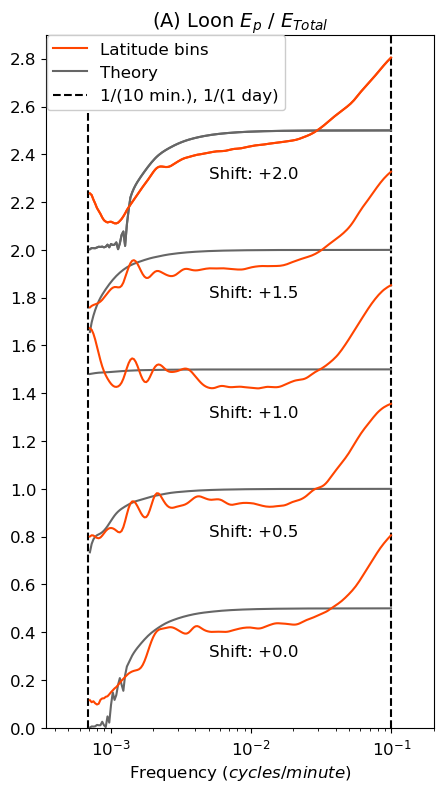

In [4]:
# Fig. S3A

offset = 0.5
ymax = 2.9
ymin = 0.0

plt.figure(figsize=(5,9))
temp1 = Ep_spectra_binned[0,:]/Etotal_spectra_binned[0,:]
temp2 = Ep_spectra_binned[1,:]/Etotal_spectra_binned[1,:]
temp3 = Ep_spectra_binned[2,:]/Etotal_spectra_binned[2,:]
temp4 = Ep_spectra_binned[3,:]/Etotal_spectra_binned[3,:]
temp5 = Ep_spectra_binned[4,:]/Etotal_spectra_binned[4,:]
plt.plot(frequency,temp1 + 4*offset,c=matplotlib.colors.CSS4_COLORS['orangered'])
plt.plot(frequency,EpEtotRatio_theory_binned[0,:] + 4*offset,color=[0.4,0.4,0.4])
plt.plot([1/10, 1/10], [ymin, ymax],'--k')
plt.plot([1/1440, 1/1440], [ymin, ymax],'--k')
plt.plot(frequency,EpEtotRatio_theory_binned[0,:] + 4*offset,color=[0.4,0.4,0.4])
plt.plot(frequency,EpEtotRatio_theory_binned[1,:] + 3*offset,color=[0.4,0.4,0.4])
plt.plot(frequency,EpEtotRatio_theory_binned[2,:] + 2*offset,color=[0.4,0.4,0.4])
plt.plot(frequency,EpEtotRatio_theory_binned[3,:] + 1*offset,color=[0.4,0.4,0.4])
plt.plot(frequency,EpEtotRatio_theory_binned[4,:] + 0*offset,color=[0.4,0.4,0.4])
plt.plot(frequency,temp1 + 4*offset,c=matplotlib.colors.CSS4_COLORS['orangered'])
plt.plot(frequency,temp2 + 3*offset,c=matplotlib.colors.CSS4_COLORS['orangered'])
plt.plot(frequency,temp3 + 2*offset,c=matplotlib.colors.CSS4_COLORS['orangered'])
plt.plot(frequency,temp4 + 1*offset,c=matplotlib.colors.CSS4_COLORS['orangered'])
plt.plot(frequency,temp5 + 0*offset,c=matplotlib.colors.CSS4_COLORS['orangered'])
plt.text(5E-3, 0.3, 'Shift: +0.0', fontsize=12)
plt.text(5E-3, 0.8, 'Shift: +0.5', fontsize=12)
plt.text(5E-3, 1.3, 'Shift: +1.0', fontsize=12)
plt.text(5E-3, 1.8, 'Shift: +1.5', fontsize=12)
plt.text(5E-3, 2.3, 'Shift: +2.0', fontsize=12)
plt.xscale('log')
plt.xlim(1/(2*24*60),1/5)
plt.ylim(ymin,ymax)
plt.xticks(fontsize=12)
plt.yticks([0.0,0.2,0.4,0.6,0.8,1,1.2,1.4,1.6,1.8,2,2.2,2.4,2.6,2.8],fontsize=12)
plt.title('(A) Loon $E_{p}$ / $E_{Total}$', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.legend(['Latitude bins','Theory','1/(10 min.), 1/(1 day)'],
           loc='upper left', bbox_to_anchor=(-0.020, 1.0115), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp31.pdf', format='pdf', bbox_inches='tight');

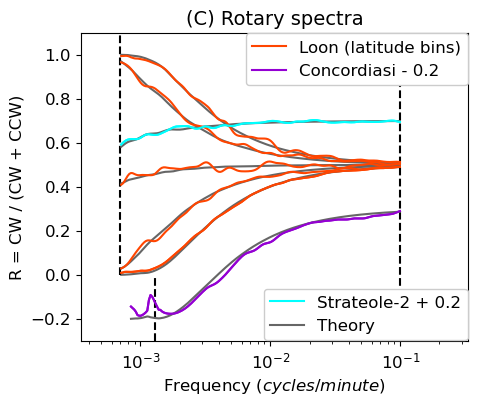

In [5]:
# Fig. S3C

container = np.load('R_energies_spectra_lat_omega0_8.npz')
data = [container[key] for key in container]
period = data[0]
lat_bin_edges = data[1]
R_spectra_binned = data[2]
R_theory_binned = data[3]
frequency = 1/period

container = np.load('../concordiasi_strateole2_analysis/Concordiasi_R_energies_spectra_omega0_8.npz')
data = [container[key] for key in container]
period_C = data[0]
R_spectra_C = data[1]
R_theory_C = data[2]
frequency_C = 1/period_C

container = np.load('../concordiasi_strateole2_analysis/Strateole2_R_energies_spectra_omega0_8.npz')
data = [container[key] for key in container]
period_S2 = data[0]
R_spectra_S2 = data[1]
R_theory_S2 = data[2]
frequency_S2 = 1/period_S2

temp_f = 2*Omega*np.sin(np.pi*70/180)
temp_f = 60*temp_f/(2*np.pi)

fig, ax = plt.subplots(figsize=(5,4))
ymin = -0.3
ymax = 1.1
ysplit = 0
line1, = ax.plot(frequency, R_spectra_binned[0,:], c=matplotlib.colors.CSS4_COLORS['orangered'],
                label = 'Loon (latitude bins)')
line2, = ax.plot(frequency_C, R_spectra_C - 0.2, c=matplotlib.colors.CSS4_COLORS['darkviolet'],
                label = 'Concordiasi - 0.2')
line3, = ax.plot(frequency_S2, R_spectra_S2 + 0.2, c=matplotlib.colors.CSS4_COLORS['cyan'],
                label = 'Strateole-2 + 0.2')
line4, = ax.plot(frequency, R_theory_binned[0,:], color=[0.4,0.4,0.4],
                label = 'Theory')
line5, = ax.plot([1/10, 1/10], [ymin, ymax],'--k',
                label = '1/(10 min.), 1/(1 day), $f$ at 70$^\circ$')
ax.plot([1/1440, 1/1440], [ysplit, ymax],'--k')
ax.plot([temp_f, temp_f], [ymin, ysplit],'--k')
ax.plot(frequency, R_theory_binned[1,:], color=[0.4,0.4,0.4])
ax.plot(frequency, R_theory_binned[2,:], color=[0.4,0.4,0.4])
ax.plot(frequency, R_theory_binned[3,:], color=[0.4,0.4,0.4])
ax.plot(frequency, R_theory_binned[4,:], color=[0.4,0.4,0.4])
ax.plot(frequency_C, R_theory_C - 0.2, color=[0.4,0.4,0.4])
ax.plot(frequency_S2, R_theory_S2 + 0.2, color=[0.4,0.4,0.4])
ax.plot(frequency, np.transpose(R_spectra_binned), 'orangered')
ax.plot(frequency_C, R_spectra_C - 0.2, 'darkviolet')
ax.plot(frequency_S2, R_spectra_S2 + 0.2, 'cyan')
ax.set_xlim(1/(2*24*60),1/3)
ax.set_ylim(ymin,ymax)
ax.set_xscale('log')
ax.set_title('(C) Rotary spectra', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
ax.set_ylabel('R = CW / (CW + CCW)', fontsize=12)
ax.tick_params(labelsize=12)
first_legend = ax.legend(handles=[line1, line2], 
                         loc='upper right', bbox_to_anchor=(1.02, 1.025), framealpha=1, fontsize=12)
ax.add_artist(first_legend)
ax.legend(handles=[line3, line4],
          loc='lower right', bbox_to_anchor=(1.02, -0.025), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp31.pdf', format='pdf', bbox_inches='tight');